# 1. Truth models and appraisal wells

**Question.** With sparse well data, which experimental variogram type (GSLIB `gamv` types 1, 4, 5, 6, 7, 8 plus the
cumulative and normal-score semivariograms) gives the best continuity model, the most accurate porosity/OOIP map, and
the best development decision? And how does that compare with simply drilling more appraisal wells?

**Workflow** (all computation lives in the `vstudy` module; these notebooks only call it and plot):

1. *This notebook*: synthetic truth models, appraisal wells, declustering.
2. `02_variograms.ipynb`: experimental variograms, azimuth inference, automatic fitting, accuracy against the truth.
3. `03_kriging_decisions.ipynb`: kriging, OOIP, uncertainty, well placement, value of information, executive summary.

The full study (4 scenarios x 30 truth models x 25/50/100 wells x random/preferential designs = 720 datasets) runs once
with `python run_study.py main` (about 5 minutes) and is cached in `results/main/`. A separate pilot
(`python run_study.py pilot`, 5 truths per scenario on different seeds) is used only to apply the type-trimming rule.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from vstudy import config as C, plots, analysis as A, wells as W, fitting, kriging
from vstudy.pipeline import run_study, build_truth, build_dataset, dataset_rng
from vstudy.variography import Truth, lag_settings
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)

## Scenarios

Four reservoirs, each chosen because a specific variogram type is expected to help there. Variograms are in Gaussian
units with a sill of 1; azimuth is clockwise from north.

In [2]:
rows = []
for s, p in C.SCENARIOS.items():
    v = p['vario']
    dist = {'gaussian': f"N({p.get('mean')}, {p.get('std')})", 'lognormal': f"lognormal, median {p.get('median')}, log-sd {p.get('log_std')}",
            'facies': f"{int(100*p.get('sand_prop', 0))}% sand N{p.get('sand')} / shale N{p.get('shale')}"}[p['transform']]
    rows.append(dict(scenario=s, porosity=dist, structure={1: 'spherical', 2: 'exponential'}[v['it']], nugget=v['nug'],
                     azimuth=v['azi'], range_major=v['hmaj'], range_minor=v['hmin']))
pd.DataFrame(rows).set_index('scenario')

,porosity,structure,nugget,azimuth,range_major,range_minor
scenario,,,,,,
gaussian,"N(0.17, 0.035)",spherical,0.10,0.0,400.0,400.0
skewed,"lognormal, median 0.12, log-sd 0.45",spherical,0.10,0.0,400.0,250.0
anisotropic,"N(0.17, 0.035)",spherical,0.05,45.0,600.0,150.0
facies,"60% sand N(0.21, 0.03) / shale N(0.06, 0.015)",spherical,0.05,-60.0,500.0,200.0


## One truth model per scenario

Truth models are unconditional Gaussian fields from FFT circulant embedding (exact covariance on the grid), re-standardized
and transformed to porosity, clipped to [0.01, 0.40]. 100 x 100 cells of 10 m.

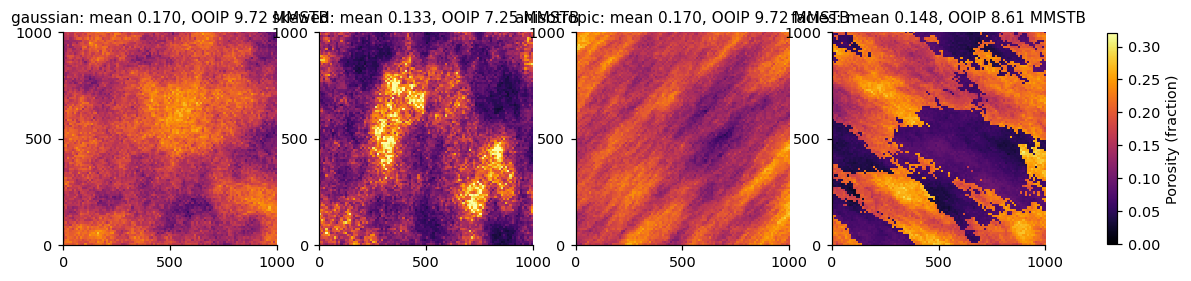

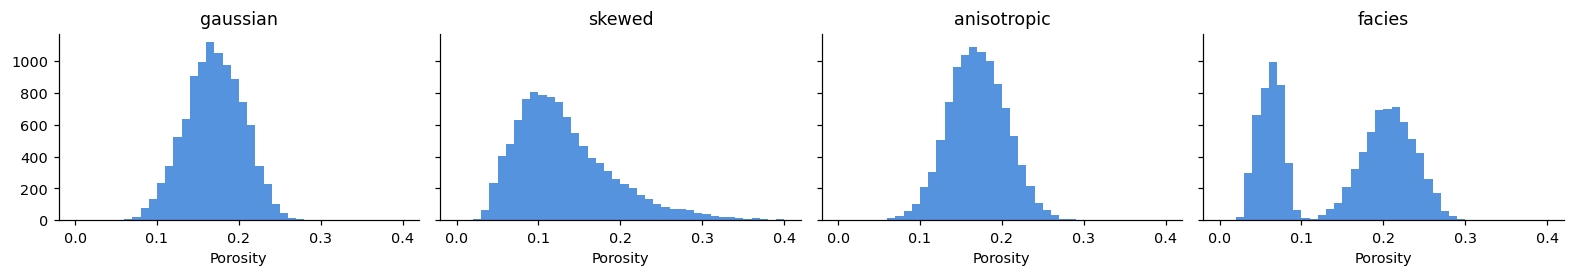

In [3]:
truths = {s: build_truth('main', s, 0)[0] for s in C.SCEN_NAMES}
fig = plots.maps([(f"{s}: mean {p.mean():.3f}, OOIP {C.ooip_total(p):.2f} MMSTB", p) for s, p in truths.items()],
                 ncols=4, vmin=0.0, vmax=0.32, size=3.6)
fig, axes = plt.subplots(1, 4, figsize=(14.4, 2.6), sharey=True)
for ax, (s, p) in zip(axes, truths.items()):
    ax.hist(p.ravel(), bins=np.linspace(0, 0.4, 41), color=plots.C_MAJ, alpha=0.8)
    ax.set_title(s); ax.set_xlabel('Porosity')
plt.tight_layout(); plt.show()

## Exhaustive variogram maps

The variogram of each complete truth model (all cell pairs, by FFT). This is the target every experimental variogram
is scored against. The dashed line marks the scenario's major direction.

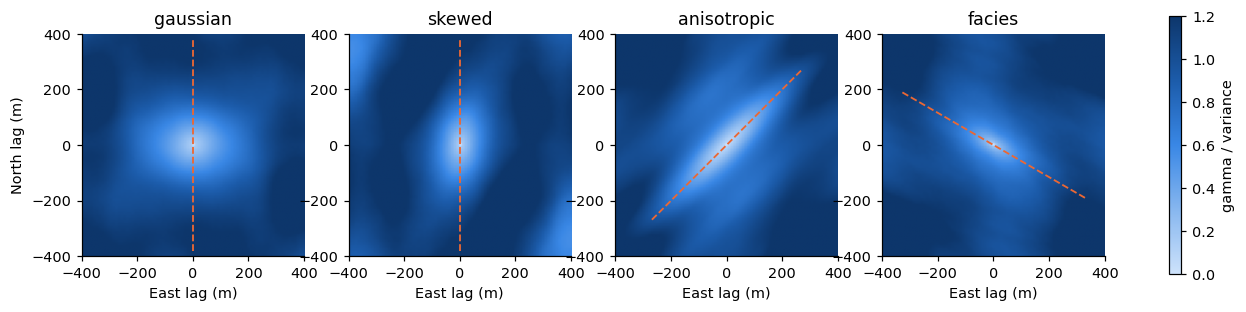

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
r = 40                                     # +/- 400 m
for ax, (s, p) in zip(axes, truths.items()):
    g = Truth(p).map[C.NY - 1 - r:C.NY + r, C.NX - 1 - r:C.NX + r]
    im = ax.imshow(g, cmap=plots.SEQ, vmin=0, vmax=1.2, extent=[-400, 400, -400, 400])
    a = np.radians(C.SCENARIOS[s]['vario']['azi'])
    ax.plot([-380 * np.sin(a), 380 * np.sin(a)], [-380 * np.cos(a), 380 * np.cos(a)], '--', color=plots.C_MIN, lw=1.2)
    ax.set_title(s); ax.set_xlabel('East lag (m)')
axes[0].set_ylabel('North lag (m)')
fig.colorbar(im, ax=axes, shrink=0.8, label='gamma / variance'); plt.show()

## Appraisal wells

Two designs at three densities. *Random*: uniform locations. *Preferential*: locations drawn with probability rising
from 0.1 to 1.0 with porosity rank, i.e. drilling the sweet spots. The regular grid of the original study is dropped:
it has no short-distance pairs, so short ranges could not be estimated from it.

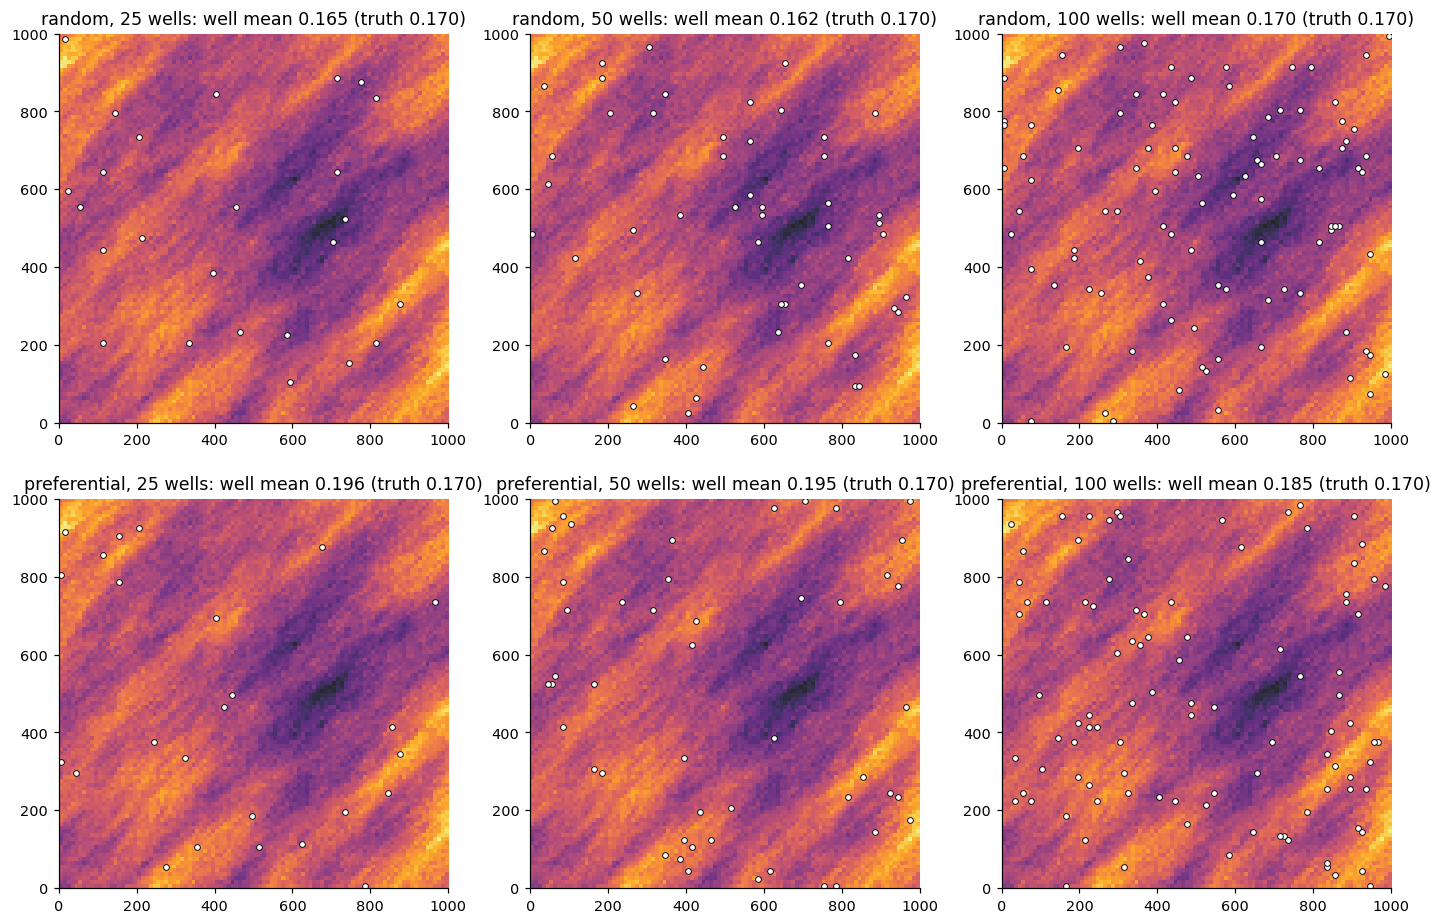

In [5]:
s = 'anisotropic'; phi = truths[s]
fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
for i, design in enumerate(C.DESIGNS):
    for j, n in enumerate(C.WELL_COUNTS):
        w = W.sample(phi, design, n, dataset_rng('main', s, 0, n, design))
        ax = axes[i, j]
        ax.imshow(phi, extent=plots.EXTENT, cmap=plots.PHI_CMAP, vmin=0.05, vmax=0.3, alpha=0.85)
        ax.scatter(w['x'], w['y'], s=14, c='white', edgecolors='black', linewidths=0.6)
        ax.set_title(f"{design}, {n} wells: well mean {w['v'].mean():.3f} (truth {phi.mean():.3f})")
plt.tight_layout(); plt.show()

## Declustering

Preferential wells over-represent high porosity. Cell declustering (GSLIB `declus` rule: the cell size that minimizes
the declustered mean, averaged over 16 grid origins) down-weights wells that share a cell. The declustered mean and
variance feed the naive estimate, the kriging variance, and the normal-score transform. Below: the bias in the mean,
raw vs declustered, over all 120 main-study truth models.

In [6]:
rows = []
for s in C.SCEN_NAMES:
    for r in range(C.N_REAL):
        phi = build_truth('main', s, r)[0]
        for n in C.WELL_COUNTS:
            for design in C.DESIGNS:
                w = W.sample(phi, design, n, dataset_rng('main', s, r, n, design))
                wt = W.decluster(w['x'], w['y'], w['v'], preferential=(design == 'preferential'))
                rows.append(dict(scenario=s, design=design, n_wells=n,
                                 raw_bias=w['v'].mean() - phi.mean(), declustered_bias=np.sum(wt * w['v']) - phi.mean()))
bias = pd.DataFrame(rows)
tab = bias.groupby(['design', 'n_wells'])[['raw_bias', 'declustered_bias']].mean()
tab['bias_removed_%'] = np.where(tab.index.get_level_values('design') == 'preferential', 100 * (1 - tab.declustered_bias / tab.raw_bias), np.nan)   # random wells have no bias to remove
tab.round(4)

raw_bias  declustered_bias  bias_removed_%
design       n_wells                                             
preferential 25       2.520e-02         1.940e-02          22.986
             50       2.380e-02         1.760e-02          25.878
             100      2.380e-02         1.550e-02          34.893
random       25       5.000e-04         1.200e-03             NaN
             50       2.000e-04         4.000e-04             NaN
             100     -1.000e-04         1.000e-04             NaN

Declustering removes part of the preferential bias, not all of it: low-porosity areas are under-sampled rather than
densely clustered, so there is little to down-weight. This residual bias carries through to OOIP and to the uncertainty
model in notebook 3.